# DSR301m – Reliability & Evaluation (Bảo)
**Phần 1: LOSO → Evaluation.** (Ablation, SHAP, Figures sẽ làm ở các bước sau.)

Pipeline: `LOSO 15-fold` → lưu dự đoán out-of-fold (OOF) → tính metrics / selective / FAR_motion / per-subject / kiểm định thống kê.


## 0. Cài đặt & cấu hình

In [1]:
!pip -q install xgboost

import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import (f1_score, accuracy_score, roc_auc_score,
                             brier_score_loss, balanced_accuracy_score)
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

SEED = 42
TAUS = [0.60, 0.70, 0.80, 0.90]      # các ngưỡng báo cáo
TAU_MAIN = 0.80
INNER_CV = "group"          # "group" (khuyến nghị) | "paper_cv3" | "random"  -> xem mục 2 và mục 10
OUT = "results"; os.makedirs(OUT, exist_ok=True)
np.random.seed(SEED)

## 1. Nạp dữ liệu
Chạy ô dưới, chọn file `wesad_wrist_features.csv` khi Colab hỏi upload (hoặc đặt sẵn file cùng thư mục / Google Drive và sửa `DATA_PATH`).

In [2]:
DATA_PATH = "wesad_wrist_features.csv"
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()                      # chọn wesad_wrist_features.csv

df = pd.read_csv(DATA_PATH)
META  = ["subject_id", "time_start_sec", "time_end_sec", "label"]
FEATS = [c for c in df.columns if c not in META]
ACC_FEATS = [c for c in FEATS if c.startswith("acc_")]

print("shape:", df.shape, "| số đặc trưng:", len(FEATS))
print("label:", df.label.value_counts().to_dict())
print("NaN:", int(df[FEATS].isna().sum().sum()))
assert len(FEATS) == 25 and df.subject_id.nunique() == 15

# đổi tên S2..S17 (không có S12) -> S1..S15, giữ ID gốc; sắp hàng THEO SỐ (cố định, quan trọng với cv=3 không shuffle)
orig_ids = sorted(df.subject_id.unique(), key=lambda s: int(s[1:]))
id_map = {old: f"S{i+1}" for i, old in enumerate(orig_ids)}
df["subject_orig"] = df.subject_id
df["sid_num"] = df.subject_id.map(lambda s: int(s[1:]))
df["subject_id"] = df.subject_id.map(id_map)
df = df.sort_values(["sid_num", "time_start_sec"]).reset_index(drop=True)
SUBJECTS = [id_map[s] for s in orig_ids]
print(id_map)
df.groupby("subject_id").label.agg(["count", "mean"]).loc[SUBJECTS].round(3)

Saving wesad_wrist_features.csv to wesad_wrist_features.csv
shape: (5294, 29) | số đặc trưng: 25
label: {0: 3412, 1: 1882}
NaN: 0
{'S2': 'S1', 'S3': 'S2', 'S4': 'S3', 'S5': 'S4', 'S6': 'S5', 'S7': 'S6', 'S8': 'S7', 'S9': 'S8', 'S10': 'S9', 'S11': 'S10', 'S13': 'S11', 'S14': 'S12', 'S15': 'S13', 'S16': 'S14', 'S17': 'S15'}


,count,mean
subject_id,,
S1,338,0.343
S2,341,0.355
S3,345,0.348
S4,353,0.343
S5,351,0.350
S6,351,0.345
S7,352,0.358
S8,350,0.346
S9,365,0.375


## 2. LOSO 15-fold
Mỗi fold: 1 subject làm test, 14 subject còn lại train. **Scaler và calibrator chỉ fit trên 14 subject train** (không leak).

Ba mô hình để so sánh (khớp Bảng III của paper): RF, XGBoost gốc, XGBoost + Isotonic.

> **Cách chia fold để hiệu chuẩn (`INNER_CV`)** – quan trọng hơn vẻ ngoài của nó:
> - `group` *(mặc định, khuyến nghị)*: GroupKFold theo subject. Cửa sổ chồng lắp 91.7% nên không được để các cửa sổ gần trùng nhau nằm ở cả hai phía; cách này cũng **không phụ thuộc thứ tự hàng**.
> - `paper_cv3`: tương đương `cv=3` mặc định của sklearn (**không shuffle**, chia theo khối liên tiếp) → kết quả **phụ thuộc thứ tự hàng của file**. Dùng để đối chiếu paper.
> - `random`: KFold ngẫu nhiên thật → bộ hiệu chuẩn thấy các cửa sổ gần trùng nhau, quá tự tin. Dùng để minh họa rủi ro.
>
> Mục 10 chạy cả ba để có bảng độ nhạy.


In [3]:
def make_xgb():
    return XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08,
                         subsample=0.8, eval_metric="logloss",
                         random_state=SEED, n_jobs=-1, verbosity=0)

def make_rf():
    return RandomForestClassifier(n_estimators=100, max_depth=5,
                                  random_state=SEED, n_jobs=-1)

def inner_cv_splits(Xtr, ytr, gtr, mode=INNER_CV, seed=SEED):
    """Cách chia fold để HIỆU CHUẨN (Isotonic) bên trong 14 subject train.
    group     : GroupKFold theo subject  -> không rò rỉ giữa các cửa sổ chồng lắp, KHÔNG phụ thuộc thứ tự hàng (khuyến nghị)
    paper_cv3 : StratifiedKFold(3) không shuffle = cv=3 mặc định của sklearn -> chia theo khối liên tiếp, PHỤ THUỘC thứ tự hàng
    random    : StratifiedKFold(3, shuffle=True) -> các cửa sổ gần trùng nhau rơi vào cả hai phía -> hiệu chuẩn quá tự tin
    """
    if mode == "group":     return list(GroupKFold(n_splits=3).split(Xtr, ytr, groups=gtr))
    if mode == "paper_cv3": return list(StratifiedKFold(n_splits=3, shuffle=False).split(Xtr, ytr))
    if mode == "random":    return list(StratifiedKFold(n_splits=3, shuffle=True, random_state=seed).split(Xtr, ytr))
    raise ValueError(mode)

def run_loso(df, feats, tag=""):
    """Trả về DataFrame OOF: mỗi dòng = 1 cửa sổ của subject test, kèm xác suất 3 mô hình."""
    X, y, g = df[feats].values, df.label.values, df.subject_id.values
    parts, t0 = [], time.time()
    for s in SUBJECTS:
        te, tr = (g == s), (g != s)
        sc  = StandardScaler().fit(X[tr])
        Xtr, Xte = sc.transform(X[tr]), sc.transform(X[te])

        p_rf  = make_rf().fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]
        p_xgb = make_xgb().fit(Xtr, y[tr]).predict_proba(Xte)[:, 1]

        inner_cv = inner_cv_splits(Xtr, y[tr], g[tr])
        cal = CalibratedClassifierCV(make_xgb(), method="isotonic", cv=inner_cv).fit(Xtr, y[tr])
        p_cal = cal.predict_proba(Xte)[:, 1]

        d = df.loc[te, META + ["acc_mag_var"]].copy()
        d["p_rf"], d["p_xgb"], d["p_cal"] = p_rf, p_xgb, p_cal
        parts.append(d)
        print(f"{tag}fold {s:>3} xong  ({time.time()-t0:5.1f}s)")
    return pd.concat(parts, ignore_index=True)

oof = run_loso(df, FEATS)
oof.to_csv(f"{OUT}/oof_predictions.csv", index=False)
oof.head()

fold  S1 xong  (  2.2s)
fold  S2 xong  (  4.3s)
fold  S3 xong  (  8.7s)
fold  S4 xong  ( 10.8s)
fold  S5 xong  ( 12.9s)
fold  S6 xong  ( 15.1s)
fold  S7 xong  ( 17.2s)
fold  S8 xong  ( 21.5s)
fold  S9 xong  ( 23.6s)
fold S10 xong  ( 25.7s)
fold S11 xong  ( 27.8s)
fold S12 xong  ( 29.9s)
fold S13 xong  ( 34.2s)
fold S14 xong  ( 36.4s)
fold S15 xong  ( 38.6s)


,subject_id,time_start_sec,time_end_sec,label,acc_mag_var,p_rf,p_xgb,p_cal
0,S1,295,355,0,46.725019,0.321238,0.339670,0.376308
1,S1,300,360,0,45.355848,0.322657,0.389731,0.469311
2,S1,305,365,0,37.769084,0.300036,0.287475,0.413843
3,S1,310,370,0,35.298618,0.271352,0.059495,0.285638
4,S1,315,375,0,35.263583,0.288625,0.055650,0.285638


## 3. Hàm đánh giá
- **ECE**: theo Eq.(6) của paper – 10 bin theo *confidence* `max(p, 1-p)`. Ngoài ra tính thêm ECE theo xác suất lớp Stress (dùng cho reliability diagram).
- **FAR_motion**: Eq.(11) – mẫu Non-Stress có `Var(ACC) ≥ θ` (θ = phân vị 80) bị đoán thành Stress; **mẫu số luôn là toàn bộ Non-Stress vận động mạnh** (kể cả mẫu bị từ chối), nên chỉ số giảm được khi mô hình từ chối là đúng ý nghĩa "báo động giả được ngăn chặn".
- **Selective F1**: paper không nói rõ là F1 lớp Stress hay macro → tính **cả hai**, cần thống nhất với nhóm.


In [4]:
y_all = oof.label.values
THETA = np.percentile(oof.acc_mag_var, 80)          # ngưỡng vận động mạnh
HM    = (oof.acc_mag_var.values >= THETA)
print(f"theta_motion (P80 Var(ACC)) = {THETA:.3f}  | High-motion = {HM.mean()*100:.1f}% mẫu")

def ece_conf(y, p, M=10):
    conf = np.maximum(p, 1 - p); corr = ((p >= .5).astype(int) == y)
    b = np.minimum(((conf - .5) / .5 * M).astype(int), M - 1); e = 0.0
    for m in range(M):
        k = b == m
        if k.any(): e += k.mean() * abs(corr[k].mean() - conf[k].mean())
    return e

def ece_pos(y, p, M=10):
    b = np.minimum((p * M).astype(int), M - 1); e = 0.0
    for m in range(M):
        k = b == m
        if k.any(): e += k.mean() * abs(y[k].mean() - p[k].mean())
    return e

def far_motion(y, pred, hm, accepted=None):
    """% Non-Stress vận động mạnh bị đoán Stress. Mẫu số = TẤT CẢ Non-Stress vận động mạnh."""
    den = ((y == 0) & hm).sum()
    if den == 0: return np.nan
    acc = np.ones_like(y, bool) if accepted is None else accepted
    return ((pred == 1) & (y == 0) & hm & acc).sum() / den * 100

def full_metrics(y, p, hm):
    pred = (p >= .5).astype(int)
    return dict(Accuracy=accuracy_score(y, pred), BalAcc=balanced_accuracy_score(y, pred),
                F1_stress=f1_score(y, pred), F1_macro=f1_score(y, pred, average="macro"),
                AUROC=roc_auc_score(y, p), Brier=brier_score_loss(y, p),
                ECE=ece_conf(y, p), ECE_pos=ece_pos(y, p), FAR_motion=far_motion(y, pred, hm))

def sel_metrics(y, p, hm, tau):
    acc  = (p >= tau) | ((1 - p) >= tau); pred = (p >= tau).astype(int)
    if acc.sum() == 0: return dict(tau=tau, Coverage=0)
    return dict(tau=tau, Coverage=acc.mean()*100,
                Sel_F1_stress=f1_score(y[acc], pred[acc], zero_division=0),
                Sel_F1_macro=f1_score(y[acc], pred[acc], average="macro", zero_division=0),
                Sel_Acc=accuracy_score(y[acc], pred[acc]),
                Sel_Risk=(pred[acc] != y[acc]).mean(),
                ECE=ece_conf(y[acc], p[acc]),
                FAR_motion=far_motion(y, pred, hm, accepted=acc),
                Cov_highmotion=acc[hm].mean()*100, Cov_lowmotion=acc[~hm].mean()*100)

theta_motion (P80 Var(ACC)) = 15.385  | High-motion = 20.0% mẫu


## 4. Bảng so sánh Full Coverage (tương ứng Bảng III, 3 dòng đầu)

In [5]:
names = {"p_rf": "Random Forest", "p_xgb": "XGBoost (gốc)", "p_cal": "XGBoost + Isotonic"}
tab_full = pd.DataFrame({n: full_metrics(y_all, oof[c].values, HM) for c, n in names.items()}).T
tab_full.to_csv(f"{OUT}/table_full_coverage.csv")
tab_full.round(4)

,Accuracy,BalAcc,F1_stress,F1_macro,AUROC,Brier,ECE,ECE_pos,FAR_motion
Random Forest,0.8921,0.8734,0.8420,0.8801,0.9587,0.0822,0.0638,0.0681,13.8983
XGBoost (gốc),0.8897,0.8871,0.8499,0.8813,0.9460,0.0927,0.0612,0.0757,12.2034
XGBoost + Isotonic,0.9090,0.8920,0.8668,0.8988,0.9552,0.0780,0.0744,0.0578,10.8475


## 5. Phân loại chọn lọc: quét ngưỡng τ (Risk–Coverage)
Dùng xác suất đã hiệu chuẩn `p_cal`.

In [6]:
p_cal = oof.p_cal.values
tab_sel = pd.DataFrame([sel_metrics(y_all, p_cal, HM, t) for t in TAUS]).set_index("tau")
tab_sel.to_csv(f"{OUT}/table_selective.csv")
display(tab_sel.round(4))

# đường cong dày hơn cho vẽ hình
tau_grid = np.round(np.arange(0.50, 0.951, 0.01), 2)
curve = pd.DataFrame([sel_metrics(y_all, p_cal, HM, t) for t in tau_grid]).set_index("tau")
curve.to_csv(f"{OUT}/risk_coverage_curve.csv")

,Coverage,Sel_F1_stress,Sel_F1_macro,Sel_Acc,Sel_Risk,ECE,FAR_motion,Cov_highmotion,Cov_lowmotion
tau,,,,,,,,,
0.6,89.7620,0.9045,0.9286,0.9367,0.0633,0.0534,7.4576,85.0803,90.9327
0.7,81.7907,0.9128,0.9368,0.9460,0.0540,0.0406,4.4068,76.2984,83.1641
0.8,69.4182,0.9315,0.9520,0.9608,0.0392,0.0290,4.0678,63.4561,70.9091
0.9,50.3778,0.9554,0.9693,0.9756,0.0244,0.0161,0.6780,40.9821,52.7273


## 6. Phân tích theo ngữ cảnh vận động (Low vs High motion)
Trả lời RQ1: model bắt buộc đoán 100% sai nhiều ở đâu, và việc từ chối lọc bỏ đúng chỗ nào?

In [7]:
rows = []
for ctx, m in [("Low motion", ~HM), ("High motion", HM)]:
    for c, n in names.items():
        p = oof[c].values[m]; yy = y_all[m]; pred = (p >= .5).astype(int)
        rows.append(dict(context=ctx, model=n, n=m.sum(),
                         Accuracy=accuracy_score(yy, pred),
                         FPR_NonStress=((pred == 1) & (yy == 0)).sum() / max((yy == 0).sum(), 1) * 100,
                         Coverage=100.0))
    for t in [0.7, 0.8]:
        p = p_cal[m]; yy = y_all[m]; acc = (p >= t) | (1 - p >= t); pred = (p >= t).astype(int)
        rows.append(dict(context=ctx, model=f"Selective τ={t}", n=m.sum(),
                         Accuracy=accuracy_score(yy[acc], pred[acc]),
                         FPR_NonStress=((pred == 1) & (yy == 0) & acc).sum() / max((yy == 0).sum(), 1) * 100,
                         Coverage=acc.mean()*100))
tab_ctx = pd.DataFrame(rows); tab_ctx.to_csv(f"{OUT}/table_motion_context.csv", index=False)
tab_ctx.round(3)

,context,model,n,Accuracy,FPR_NonStress,Coverage
0,Low motion,Random Forest,4235,0.898,5.454,100.000
1,Low motion,XGBoost (gốc),4235,0.881,10.234,100.000
2,Low motion,XGBoost + Isotonic,4235,0.919,4.363,100.000
3,Low motion,Selective τ=0.7,4235,0.941,1.989,83.164
4,Low motion,Selective τ=0.8,4235,0.957,1.412,70.909
5,High motion,Random Forest,1059,0.871,13.898,100.000
6,High motion,XGBoost (gốc),1059,0.924,12.203,100.000
7,High motion,XGBoost + Isotonic,1059,0.869,10.847,100.000
8,High motion,Selective τ=0.7,1059,0.968,4.407,76.298
9,High motion,Selective τ=0.8,1059,0.979,4.068,63.456


## 7. Phân tích theo từng subject (per-subject)
Quan trọng cho tính đáng tin: trung bình đẹp có thể che giấu vài subject rất tệ.

In [8]:
sub_rows = []
for s in SUBJECTS:
    m = (oof.subject_id == s).values
    y, hm = y_all[m], HM[m]
    r = dict(subject=s, n=m.sum(), stress_ratio=y.mean(), highmotion_ratio=hm.mean())
    for c, n in names.items():
        p = oof[c].values[m]; pred = (p >= .5).astype(int)
        r[f"F1_{c}"]  = f1_score(y, pred, zero_division=0)
        r[f"ECE_{c}"] = ece_conf(y, p)
        r[f"FAR_{c}"] = far_motion(y, pred, hm)
    pc = p_cal[m]; acc = (pc >= TAU_MAIN) | (1 - pc >= TAU_MAIN); pred = (pc >= TAU_MAIN).astype(int)
    r["Coverage_sel"] = acc.mean()*100
    r["F1_sel"] = f1_score(y[acc], pred[acc], zero_division=0) if acc.sum() else np.nan
    r["Acc_sel"] = accuracy_score(y[acc], pred[acc]) if acc.sum() else np.nan
    r["FAR_sel"] = far_motion(y, pred, hm, accepted=acc)
    sub_rows.append(r)
per_sub = pd.DataFrame(sub_rows).set_index("subject")
per_sub.to_csv(f"{OUT}/per_subject_metrics.csv")

cols = ["n", "stress_ratio", "highmotion_ratio", "F1_p_cal", "ECE_p_cal", "FAR_p_cal",
        "Coverage_sel", "F1_sel", "Acc_sel", "FAR_sel"]
display(per_sub[cols].round(3))
print("Subject F1_sel thấp nhất :", per_sub.F1_sel.idxmin(), round(per_sub.F1_sel.min(), 3))
print("Subject Coverage thấp nhất:", per_sub.Coverage_sel.idxmin(), round(per_sub.Coverage_sel.min(), 1), "%")
print("F1_sel mean ± std (giữa subject):", round(per_sub.F1_sel.mean(), 3), "±", round(per_sub.F1_sel.std(), 3))

,n,stress_ratio,highmotion_ratio,F1_p_cal,ECE_p_cal,FAR_p_cal,Coverage_sel,F1_sel,Acc_sel,FAR_sel
subject,,,,,,,,,,
S1,338,0.343,0.189,0.718,0.092,0.000,73.077,0.176,0.887,0.000
S2,341,0.355,0.240,0.712,0.129,63.636,59.824,0.811,0.770,54.545
S3,345,0.348,0.151,1.000,0.029,0.000,100.000,1.000,1.000,0.000
S4,353,0.343,0.054,0.921,0.078,78.947,71.671,0.960,0.976,31.579
S5,351,0.350,0.046,0.942,0.144,7.143,53.846,1.000,1.000,0.000
S6,351,0.345,0.174,0.906,0.120,NaN,60.399,0.986,0.986,NaN
S7,352,0.358,0.247,0.909,0.090,0.000,84.091,0.978,0.990,0.000
S8,350,0.346,0.086,0.648,0.142,0.000,87.429,0.547,0.843,0.000
S9,365,0.375,0.162,0.986,0.312,0.000,14.795,1.000,1.000,0.000


Subject F1_sel thấp nhất : S12 0.0
Subject Coverage thấp nhất: S9 14.8 %
F1_sel mean ± std (giữa subject): 0.831 ± 0.326


## 8. Kiểm định thống kê (cấp subject, N = 15)
- **Wilcoxon signed-rank cặp** trên giá trị theo từng subject (tránh pseudo-replication do cửa sổ chồng lắp).
- **Cluster bootstrap theo subject** (resample 15 subject có hoàn lại) để lấy 95% CI cho các metric gộp.

In [9]:
def paired_wilcoxon(a, b, name):
    a, b = np.asarray(a, float), np.asarray(b, float)
    ok = ~(np.isnan(a) | np.isnan(b)); a, b = a[ok], b[ok]
    d = a - b
    if np.allclose(d, 0): return dict(test=name, n=len(d), median_diff=0, W=np.nan, p=1.0, rank_biserial=0)
    W, p = wilcoxon(a, b, alternative="two-sided", zero_method="wilcox")
    nz = d[d != 0]; ranks = pd.Series(np.abs(nz)).rank().values
    rbc = (ranks[nz > 0].sum() - ranks[nz < 0].sum()) / ranks.sum()   # matched-pairs rank-biserial
    return dict(test=name, n=len(d), median_diff=np.median(d), W=W, p=p, rank_biserial=rbc)

T = per_sub
tests = [
  paired_wilcoxon(T.ECE_p_xgb, T.ECE_p_cal, "ECE: XGB gốc vs Isotonic"),
  paired_wilcoxon(T.FAR_p_xgb, T.FAR_p_cal, "FAR_motion: XGB gốc vs Isotonic"),
  paired_wilcoxon(T.FAR_p_cal, T.FAR_sel,   f"FAR_motion: Isotonic vs Selective τ={TAU_MAIN}"),
  paired_wilcoxon(T.FAR_p_xgb, T.FAR_sel,   f"FAR_motion: XGB gốc vs Selective τ={TAU_MAIN}"),
  paired_wilcoxon(T.F1_p_cal,  T.F1_sel,    f"F1: Isotonic (100%) vs Selective τ={TAU_MAIN}"),
  paired_wilcoxon(T.F1_p_xgb,  T.F1_p_cal,  "F1: XGB gốc vs Isotonic"),
]
tab_tests = pd.DataFrame(tests).set_index("test"); tab_tests.to_csv(f"{OUT}/table_wilcoxon.csv")
display(tab_tests.round(4))
print("Lưu ý: N=15 → p tối thiểu của Wilcoxon hai phía ≈ 0.00006; nếu có nhiều phép thử thì nên hiệu chỉnh Holm/Bonferroni.")

# ---- cluster bootstrap theo subject ----
rng = np.random.default_rng(SEED); B = 1000
grp = {s: np.where(oof.subject_id.values == s)[0] for s in SUBJECTS}
def pooled(idx):
    y, hm, p = y_all[idx], HM[idx], p_cal[idx]
    pred0 = (p >= .5).astype(int); s = sel_metrics(y, p, hm, TAU_MAIN)
    return dict(F1_full=f1_score(y, pred0), ECE_full=ece_conf(y, p), FAR_full=far_motion(y, pred0, hm),
                Coverage_sel=s["Coverage"], F1_sel=s["Sel_F1_stress"], FAR_sel=s["FAR_motion"])
boot = []
for _ in range(B):
    pick = rng.choice(SUBJECTS, len(SUBJECTS), replace=True)
    boot.append(pooled(np.concatenate([grp[s] for s in pick])))
boot = pd.DataFrame(boot)
ci = pd.DataFrame({"point": pd.Series(pooled(np.arange(len(oof)))),
                   "CI95_low": boot.quantile(.025), "CI95_high": boot.quantile(.975)})
ci.to_csv(f"{OUT}/bootstrap_ci.csv"); ci.round(4)

,n,median_diff,W,p,rank_biserial
test,,,,,
ECE: XGB gốc vs Isotonic,15,-0.0417,11.0,0.0034,-0.8167
FAR_motion: XGB gốc vs Isotonic,13,0.0000,4.0,0.8750,0.2000
FAR_motion: Isotonic vs Selective τ=0.8,13,0.0000,0.0,0.0625,1.0000
FAR_motion: XGB gốc vs Selective τ=0.8,13,0.0000,2.0,0.0938,0.8095
F1: Isotonic (100%) vs Selective τ=0.8,15,-0.0394,31.0,0.5303,-0.2051
F1: XGB gốc vs Isotonic,15,0.0000,45.0,0.9721,-0.0110


Lưu ý: N=15 → p tối thiểu của Wilcoxon hai phía ≈ 0.00006; nếu có nhiều phép thử thì nên hiệu chỉnh Holm/Bonferroni.


,point,CI95_low,CI95_high
F1_full,0.8668,0.7763,0.9337
ECE_full,0.0744,0.0456,0.1252
FAR_full,10.8475,2.2139,25.9459
Coverage_sel,69.4182,58.3391,79.8415
F1_sel,0.9315,0.8480,0.9854
FAR_sel,4.0678,0.0000,11.0711


## 9. Hình: Risk–Coverage, Reliability diagram, FAR_motion, per-subject

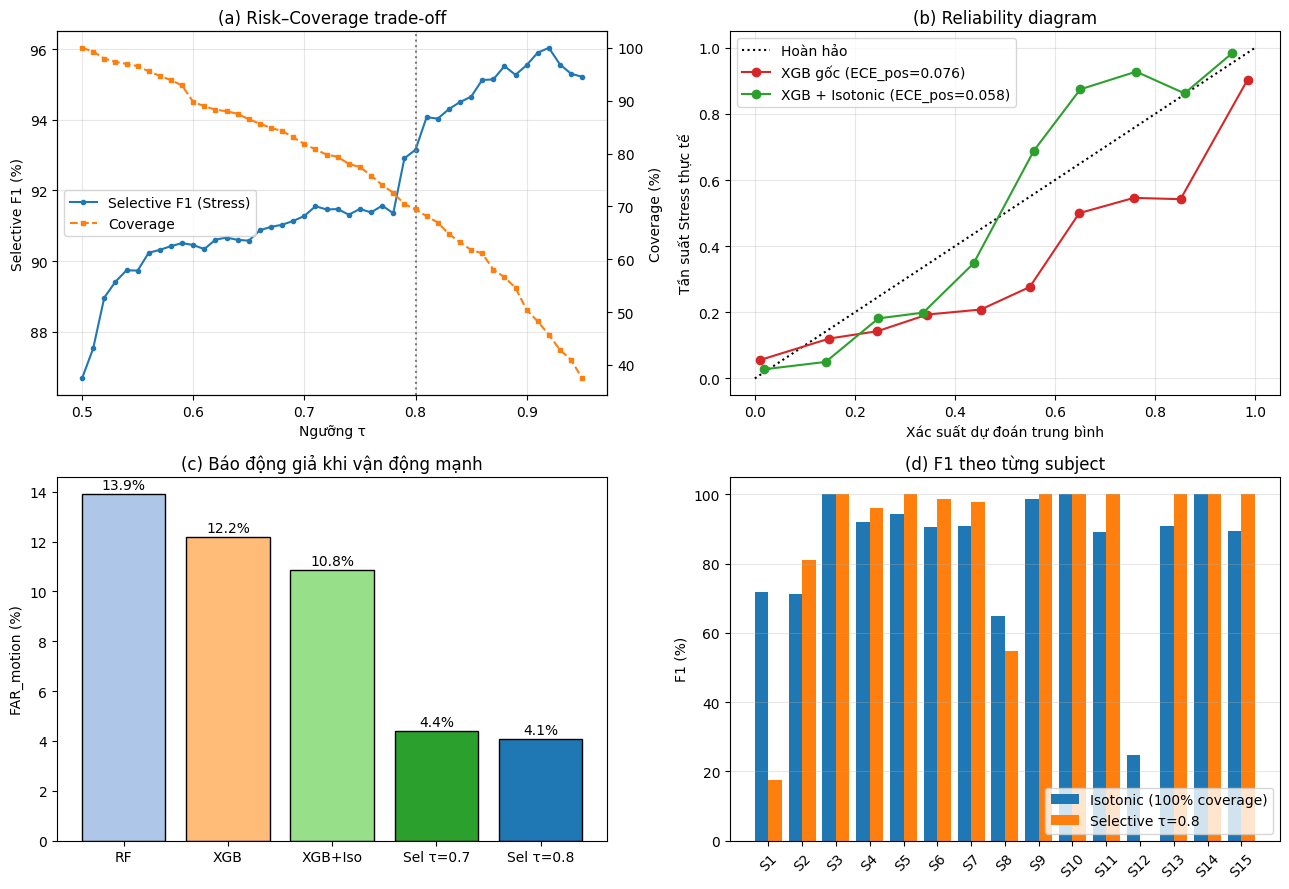

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# (a) Risk-Coverage
a = ax[0, 0]; a.plot(curve.index, curve.Sel_F1_stress*100, "o-", ms=3, label="Selective F1 (Stress)")
a.set_xlabel("Ngưỡng τ"); a.set_ylabel("Selective F1 (%)"); a.grid(alpha=.3)
a2 = a.twinx(); a2.plot(curve.index, curve.Coverage, "s--", c="tab:orange", ms=3, label="Coverage")
a2.set_ylabel("Coverage (%)"); a.axvline(TAU_MAIN, c="gray", ls=":"); a.set_title("(a) Risk–Coverage trade-off")
h1, l1 = a.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); a.legend(h1+h2, l1+l2, loc="center left")

# (b) Reliability
b = ax[0, 1]; b.plot([0, 1], [0, 1], "k:", label="Hoàn hảo")
bins = np.linspace(0, 1, 11)
for c, n, col in [("p_xgb", "XGB gốc", "tab:red"), ("p_cal", "XGB + Isotonic", "tab:green")]:
    p = oof[c].values; idx = np.minimum((p * 10).astype(int), 9)
    xs = [p[idx == k].mean() for k in range(10) if (idx == k).sum() >= 10]
    ys = [y_all[idx == k].mean() for k in range(10) if (idx == k).sum() >= 10]
    b.plot(xs, ys, "o-", c=col, label=f"{n} (ECE_pos={ece_pos(y_all, p):.3f})")
b.set_xlabel("Xác suất dự đoán trung bình"); b.set_ylabel("Tần suất Stress thực tế")
b.set_title("(b) Reliability diagram"); b.legend(); b.grid(alpha=.3)

# (c) FAR_motion
c_ = ax[1, 0]
labels = ["RF", "XGB", "XGB+Iso", "Sel τ=0.7", "Sel τ=0.8"]
vals = [tab_full.loc["Random Forest", "FAR_motion"], tab_full.loc["XGBoost (gốc)", "FAR_motion"],
        tab_full.loc["XGBoost + Isotonic", "FAR_motion"],
        tab_sel.loc[0.7, "FAR_motion"], tab_sel.loc[0.8, "FAR_motion"]]
bars = c_.bar(labels, vals, color=["#aec7e8", "#ffbb78", "#98df8a", "#2ca02c", "#1f77b4"], edgecolor="k")
for r, v in zip(bars, vals): c_.text(r.get_x()+r.get_width()/2, v+.2, f"{v:.1f}%", ha="center")
c_.set_ylabel("FAR_motion (%)"); c_.set_title("(c) Báo động giả khi vận động mạnh")

# (d) Per-subject
d_ = ax[1, 1]; x = np.arange(len(SUBJECTS)); w = .4
d_.bar(x - w/2, per_sub.F1_p_cal*100, w, label="Isotonic (100% coverage)")
d_.bar(x + w/2, per_sub.F1_sel*100,   w, label=f"Selective τ={TAU_MAIN}")
d_.set_xticks(x); d_.set_xticklabels(SUBJECTS, rotation=45); d_.set_ylabel("F1 (%)")
d_.set_title("(d) F1 theo từng subject"); d_.legend(loc="lower right"); d_.grid(axis="y", alpha=.3)

plt.tight_layout(); plt.savefig(f"{OUT}/fig_evaluation.png", dpi=200); plt.show()

## 10. Độ nhạy với cách chia fold hiệu chuẩn (INNER_CV)
Chạy lại **chỉ XGBoost + Isotonic** (cùng LOSO, cùng seed) với các cách chia fold hiệu chuẩn khác nhau. Mất thêm vài phút. Nếu kết quả đổi mạnh theo cách chia thì phải ghi rõ trong báo cáo.

In [11]:
def run_cal(d, mode, seed=SEED):
    Xd, yd, gd = d[FEATS].values, d.label.values, d.subject_id.values
    P = np.zeros(len(d))
    for s_ in SUBJECTS:
        te, tr = gd == s_, gd != s_
        sc = StandardScaler().fit(Xd[tr]); Xtr = sc.transform(Xd[tr])
        cv = inner_cv_splits(Xtr, yd[tr], gd[tr], mode=mode, seed=seed)
        cal = CalibratedClassifierCV(make_xgb(), method="isotonic", cv=cv).fit(Xtr, yd[tr])
        P[te] = cal.predict_proba(sc.transform(Xd[te]))[:, 1]
    return P

df_num = df                                                            # thứ tự S1..S15
df_str = df.sort_values(["subject_orig", "time_start_sec"]).reset_index(drop=True)   # thứ tự chuỗi: S10, S11, ..., S2
scen = [("group (khuyến nghị)", df_num, "group", SEED),
        ("paper cv=3, hàng theo số S2→S17", df_num, "paper_cv3", SEED),
        ("paper cv=3, hàng theo chuỗi S10,S11,…,S2", df_str, "paper_cv3", SEED),
        ("random shuffle, seed 0", df_num, "random", 0),
        ("random shuffle, seed 1", df_num, "random", 1),
        ("random shuffle, seed 2", df_num, "random", 2)]
rows = []
for name, d, mode, sd in scen:
    P = run_cal(d, mode, sd); yd = d.label.values; hmd = (d.acc_mag_var.values >= THETA)
    f, s_ = full_metrics(yd, P, hmd), sel_metrics(yd, P, hmd, TAU_MAIN)
    rows.append({"cách chia": name, "Coverage": s_["Coverage"], "Sel_F1_stress": s_["Sel_F1_stress"], "Sel_F1_macro": s_["Sel_F1_macro"],
                 "ECE_full": f["ECE"], "FAR_full": f["FAR_motion"], "FAR_sel": s_["FAR_motion"]})
    print(f"xong: {name}")
tab_cvsens = pd.DataFrame(rows).set_index("cách chia"); tab_cvsens.to_csv(f"{OUT}/table_inner_cv_sensitivity.csv")
tab_cvsens.round(4)

xong: group (khuyến nghị)
xong: paper cv=3, hàng theo số S2→S17
xong: paper cv=3, hàng theo chuỗi S10,S11,…,S2
xong: random shuffle, seed 0
xong: random shuffle, seed 1
xong: random shuffle, seed 2


,Coverage,Sel_F1_stress,Sel_F1_macro,ECE_full,FAR_full,FAR_sel
cách chia,,,,,,
group (khuyến nghị),69.4182,0.9315,0.9520,0.0744,10.8475,4.0678
"paper cv=3, hàng theo số S2→S17",69.2671,0.9506,0.9651,0.0453,7.1186,0.3390
"paper cv=3, hàng theo chuỗi S10,S11,…,S2",77.4273,0.9117,0.9361,0.0469,13.2203,1.6949
"random shuffle, seed 0",94.1443,0.8801,0.9076,0.0781,12.2034,9.1525
"random shuffle, seed 1",94.6921,0.8724,0.9021,0.0845,12.2034,8.1356
"random shuffle, seed 2",93.9554,0.8724,0.9016,0.0835,12.8814,8.4746


## 11. Tóm tắt nhanh để dán vào báo cáo

In [12]:
s = tab_sel.loc[TAU_MAIN]; f = tab_full.loc["XGBoost + Isotonic"]; x = tab_full.loc["XGBoost (gốc)"]
print(f"θ_motion = {THETA:.3f}")
print(f"XGB gốc      : F1={x.F1_stress:.4f} (macro {x.F1_macro:.4f})  ECE={x.ECE:.4f}  FAR_motion={x.FAR_motion:.2f}%")
print(f"XGB + Iso    : F1={f.F1_stress:.4f} (macro {f.F1_macro:.4f})  ECE={f.ECE:.4f}  FAR_motion={f.FAR_motion:.2f}%")
print(f"Selective τ={TAU_MAIN}: Coverage={s.Coverage:.2f}%  F1={s.Sel_F1_stress:.4f} (macro {s.Sel_F1_macro:.4f})  "
      f"ECE={s.ECE:.4f}  FAR_motion={s.FAR_motion:.2f}%")
print(f"FAR_motion giảm: {(1 - s.FAR_motion/f.FAR_motion)*100:.1f}% so với Isotonic, "
      f"{(1 - s.FAR_motion/x.FAR_motion)*100:.1f}% so với XGB gốc")
print(f"Coverage trong vận động mạnh: {s.Cov_highmotion:.1f}%  | vận động nhẹ: {s.Cov_lowmotion:.1f}%")

θ_motion = 15.385
XGB gốc      : F1=0.8499 (macro 0.8813)  ECE=0.0612  FAR_motion=12.20%
XGB + Iso    : F1=0.8668 (macro 0.8988)  ECE=0.0744  FAR_motion=10.85%
Selective τ=0.8: Coverage=69.42%  F1=0.9315 (macro 0.9520)  ECE=0.0290  FAR_motion=4.07%
FAR_motion giảm: 62.5% so với Isotonic, 66.7% so với XGB gốc
Coverage trong vận động mạnh: 63.5%  | vận động nhẹ: 70.9%


Tất cả file kết quả nằm trong thư mục `results/` (nhớ tải về hoặc mount Drive):
`oof_predictions.csv`, `table_*.csv` (gồm `table_inner_cv_sensitivity.csv`), `per_subject_metrics.csv`, `bootstrap_ci.csv`, `fig_evaluation.png`.

**Bước tiếp theo:** Ablation (bỏ 6 đặc trưng `acc_*`, chạy lại `run_loso(df, [f for f in FEATS if f not in ACC_FEATS])` rồi dùng lại đúng các hàm ở mục 3).

In [13]:
from google.colab import drive
import shutil, os, datetime

drive.mount('/content/drive')
DRIVE_DIR = "/content/drive/MyDrive/DSR301m_project_group4/result/LOSO"
os.makedirs(DRIVE_DIR, exist_ok=True)

shutil.copytree(OUT, DRIVE_DIR, dirs_exist_ok=True)   # OUT = "results"
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")
shutil.copy(f"{OUT}/oof_predictions.csv", f"{DRIVE_DIR}/oof_predictions_{INNER_CV}_{stamp}.csv")

print("Đã lưu vào:", DRIVE_DIR)
print(sorted(os.listdir(DRIVE_DIR)))

Mounted at /content/drive
Đã lưu vào: /content/drive/MyDrive/DSR301m_project_group4/result/LOSO
['bootstrap_ci.csv', 'fig_evaluation.png', 'oof_predictions.csv', 'oof_predictions_group_20261011_0856.csv', 'per_subject_metrics.csv', 'risk_coverage_curve.csv', 'table_full_coverage.csv', 'table_inner_cv_sensitivity.csv', 'table_motion_context.csv', 'table_selective.csv', 'table_wilcoxon.csv']
